# 10 Minute School — Viral Video Classifier
**Goal:** Predict whether a video will go viral (top 10% views) using ML  
**Model:** LightGBM Classifier  
**Features:** Video length · Subject · Upload month · Day of week · Like rate  
**Stack:** Pandas · Scikit-learn · LightGBM · Matplotlib · Seaborn

## 1. Setup & Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, ConfusionMatrixDisplay
)
from sklearn.dummy import DummyClassifier
import lightgbm as lgb
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')

df = pd.read_csv('10ms_videos.csv')
print(f'Loaded {len(df):,} videos')
df.head(3)

Loaded 2,845 videos


,video_id,title,published,views,likes,comments,duration_sec,duration_min
0,bkbtcqCa3zQ,🔴 LIVE: HSC 26 Supplementary পরীক্ষার ICT-এর C...,2026-11-15,654,26,1,1500,25.000000
1,5ehxn--aE5o,টেস্ট বা যেকোনো পরীক্ষায় Economics-এ ভালো করত...,2026-11-14,1470,93,13,2253,37.550000
2,ZghX5azrns8,Formal Letter-এ ভালো মার্কস পেতে এই ভিডিওটি তো...,2026-11-13,399,17,1,211,3.516667


## 2. Feature Engineering

In [2]:
# ── Subject tagging ───────────────────────────────────────────────────────────
SUBJECTS = {
    'HSC':        ['hsc', 'higher secondary'],
    'SSC':        ['ssc', 'secondary'],
    'Physics':    ['physics', 'পদার্থ'],
    'Chemistry':  ['chemistry', 'রসায়ন'],
    'Biology':    ['biology', 'জীববিজ্ঞান'],
    'Math':       ['math', 'গণিত', 'algebra', 'calculus'],
    'English':    ['english', 'grammar', 'vocabulary'],
    'Bangla':     ['bangla', 'বাংলা'],
    'ICT':        ['ict', 'programming', 'python', 'computer'],
    'Admission':  ['admission', 'ভর্তি'],
    'Motivation': ['motivation', 'motivational', 'life'],
    'BCS':        ['bcs', 'government job'],
}

def tag_subject(title):
    t = str(title).lower()
    for subj, kws in SUBJECTS.items():
        if any(k in t for k in kws):
            return subj
    return 'Other'

df['subject'] = df['title'].apply(tag_subject)

# ── Date features ─────────────────────────────────────────────────────────────
df['published'] = pd.to_datetime(df['published'])
df['upload_month']   = df['published'].dt.month          # 1–12 (seasonality)
df['upload_dow']     = df['published'].dt.dayofweek      # 0=Mon … 6=Sun
df['upload_year']    = df['published'].dt.year
df['days_since_pub'] = (pd.Timestamp.today() - df['published']).dt.days

# ── Engagement rate (likes per view) ─────────────────────────────────────────
df['like_rate'] = df['likes'] / df['views'].replace(0, 1)

# ── Duration buckets ─────────────────────────────────────────────────────────
def dur_bucket(m):
    if m < 5:   return 'short'
    if m < 15:  return 'medium'
    if m < 30:  return 'long'
    return 'very_long'

df['dur_bucket'] = df['duration_min'].apply(dur_bucket)

# ── Target: viral = top 10% by views ─────────────────────────────────────────
threshold = df['views'].quantile(0.90)
df['viral'] = (df['views'] >= threshold).astype(int)

print(f'Viral threshold (top 10%): {threshold:,.0f} views')
print(f'Viral videos : {df["viral"].sum():,} ({df["viral"].mean()*100:.1f}%)')
print(f'Normal videos: {(df["viral"]==0).sum():,}')
df[['title','views','subject','upload_month','upload_dow','dur_bucket','viral']].head()

Viral threshold (top 10%): 76,245 views
Viral videos : 285 (10.0%)
Normal videos: 2,560


,title,views,subject,upload_month,upload_dow,dur_bucket,viral
0,🔴 LIVE: HSC 26 Supplementary পরীক্ষার ICT-এর C...,654,HSC,11,6,long,0
1,টেস্ট বা যেকোনো পরীক্ষায় Economics-এ ভালো করত...,1470,HSC,11,5,very_long,0
2,Formal Letter-এ ভালো মার্কস পেতে এই ভিডিওটি তো...,399,Other,11,4,short,0
3,"HSC 27, টেস্ট পরীক্ষা থেকে HSC-প্রস্তুতি গুছিয...",3389,HSC,11,4,short,0
4,"এই পরীক্ষাও শেষ হবে, শুধু নিজের ওপর বিশ্বাস রা...",1011,Other,11,2,short,0


## 3. Exploratory Look at Viral vs Normal

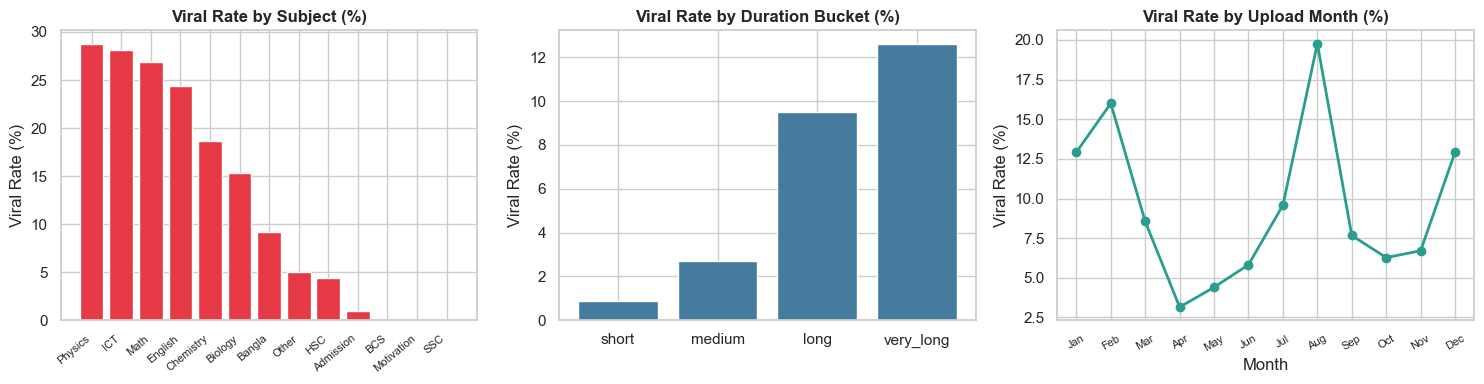

✅ EDA chart saved as eda_viral_patterns.png


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# A) Viral rate by subject
subj_viral = df.groupby('subject')['viral'].mean().sort_values(ascending=False)
axes[0].bar(subj_viral.index, subj_viral.values * 100, color='#E63946')
axes[0].set_title('Viral Rate by Subject (%)', fontweight='bold')
axes[0].set_xticklabels(subj_viral.index, rotation=40, ha='right', fontsize=8)
axes[0].set_ylabel('Viral Rate (%)')

# B) Viral rate by duration bucket
dur_order = ['short', 'medium', 'long', 'very_long']
dur_viral = df.groupby('dur_bucket')['viral'].mean().reindex(dur_order) * 100
axes[1].bar(dur_viral.index, dur_viral.values, color='#457B9D')
axes[1].set_title('Viral Rate by Duration Bucket (%)', fontweight='bold')
axes[1].set_ylabel('Viral Rate (%)')

# C) Upload month vs viral rate
month_viral = df.groupby('upload_month')['viral'].mean() * 100
axes[2].plot(month_viral.index, month_viral.values, marker='o', color='#2A9D8F', linewidth=2)
axes[2].set_title('Viral Rate by Upload Month (%)', fontweight='bold')
axes[2].set_xlabel('Month')
axes[2].set_ylabel('Viral Rate (%)')
axes[2].set_xticks(range(1, 13))
axes[2].set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], rotation=30, fontsize=8)

plt.tight_layout()
plt.show()
print('✅ EDA chart saved as eda_viral_patterns.png')

## 4. Prepare Features & Train/Test Split

In [4]:
# Encode categoricals
le_subj = LabelEncoder()
le_dur  = LabelEncoder()
df['subject_enc']    = le_subj.fit_transform(df['subject'])
df['dur_bucket_enc'] = le_dur.fit_transform(df['dur_bucket'])

FEATURES = [
    'duration_min',    # raw video length
    'subject_enc',     # subject category
    'upload_month',    # month of year
    'upload_dow',      # day of week
    'upload_year',     # year (channel growth over time)
    'dur_bucket_enc',  # short / medium / long / very_long
    'like_rate',       # engagement proxy
    'days_since_pub',  # older videos have more time to accumulate views
]

X = df[FEATURES]
y = df['viral']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Train: {len(X_train):,} samples | Test: {len(X_test):,} samples')
print(f'Viral in train: {y_train.sum()} | Viral in test: {y_test.sum()}')

Train: 2,276 samples | Test: 569 samples
Viral in train: 228 | Viral in test: 57


## 5. Train LightGBM Classifier

In [5]:
model = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    class_weight='balanced',   # handles class imbalance (90% normal, 10% viral)
    random_state=42,
    verbose=-1
)

model.fit(X_train, y_train)

# Cross-validation on training set
cv_scores = cross_val_score(
    model, X_train, y_train,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='roc_auc'
)
print(f'Cross-val ROC-AUC: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}')

# Baseline comparison
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
dummy_auc = roc_auc_score(y_test, dummy.predict_proba(X_test)[:, 1])
model_auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
print(f'\nBaseline (always predict normal) AUC: {dummy_auc:.3f}')
print(f'LightGBM AUC                        : {model_auc:.3f}')
print(f'Improvement over baseline           : +{(model_auc - dummy_auc):.3f}')

Cross-val ROC-AUC: 0.928 ± 0.012

Baseline (always predict normal) AUC: 0.500
LightGBM AUC                        : 0.940
Improvement over baseline           : +0.440


## 6. Evaluation — Confusion Matrix & ROC Curve

Classification Report:
              precision    recall  f1-score   support

      Normal       0.96      0.95      0.95       512
       Viral       0.58      0.63      0.61        57

    accuracy                           0.92       569
   macro avg       0.77      0.79      0.78       569
weighted avg       0.92      0.92      0.92       569



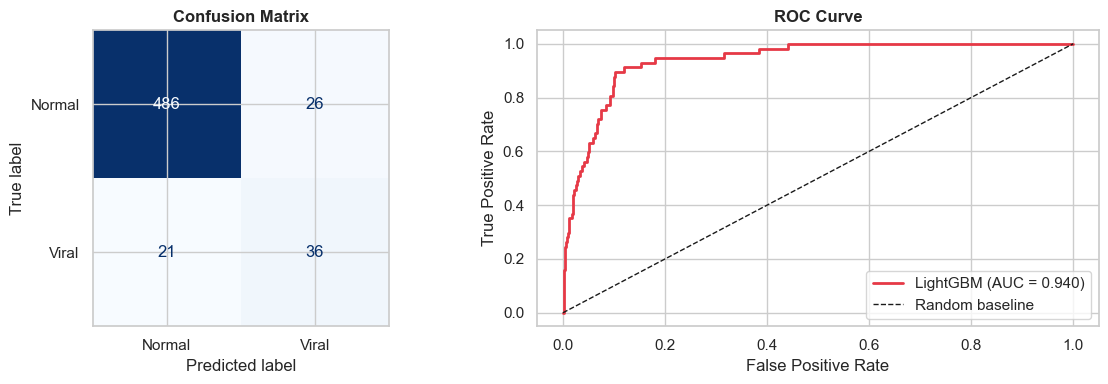

In [ ]:
y_pred       = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

print('Classification Report:')
print(classification_report(y_test, y_pred, target_names=['Normal', 'Viral']))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal', 'Viral'])
disp.plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Confusion Matrix', fontweight='bold')

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
axes[1].plot(fpr, tpr, color='#E63946', lw=2, label=f'LightGBM (AUC = {model_auc:.3f})')
axes[1].plot([0,1],[0,1], 'k--', lw=1, label='Random baseline')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

## 7. Feature Importance — What Makes a Video Go Viral?

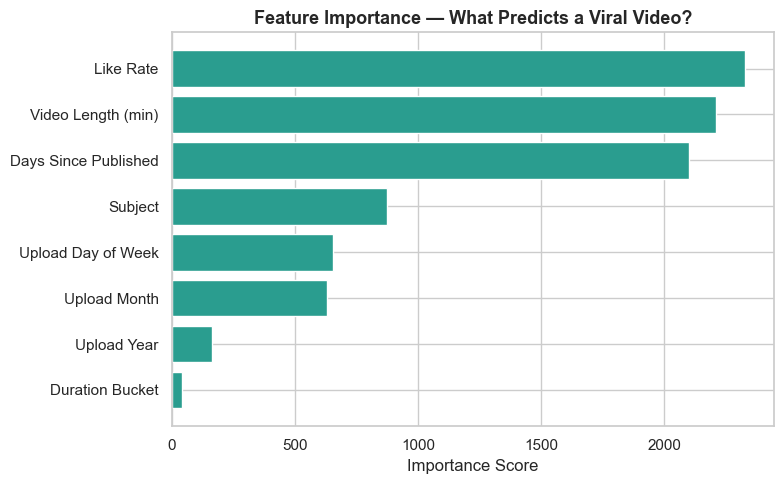

In [ ]:
importance = pd.DataFrame({
    'feature':    FEATURES,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importance['feature'], importance['importance'], color='#2A9D8F')
ax.set_title('Feature Importance — What Predicts a Viral Video?', fontweight='bold', fontsize=13)
ax.set_xlabel('Importance Score')

# Clean labels
labels = {
    'duration_min':    'Video Length (min)',
    'subject_enc':     'Subject',
    'upload_month':    'Upload Month',
    'upload_dow':      'Upload Day of Week',
    'upload_year':     'Upload Year',
    'dur_bucket_enc':  'Duration Bucket',
    'like_rate':       'Like Rate',
    'days_since_pub':  'Days Since Published',
}
ax.set_yticklabels([labels.get(f, f) for f in importance['feature']])
plt.tight_layout()
plt.show()

## 8. Predict Viral Probability for Any New Video

In [8]:
def predict_viral(title, duration_min, upload_month, upload_dow=1, upload_year=2025):
    """
    Predict viral probability for a hypothetical new video.
    
    Parameters:
    - title        : video title (used for subject tagging)
    - duration_min : video length in minutes
    - upload_month : 1–12
    - upload_dow   : 0=Mon, 1=Tue, ..., 6=Sun
    - upload_year  : year of upload
    """
    subject      = tag_subject(title)
    subject_enc  = le_subj.transform([subject])[0] if subject in le_subj.classes_ else 0
    dur_b        = dur_bucket(duration_min)
    dur_b_enc    = le_dur.transform([dur_b])[0]
    days_since   = (pd.Timestamp.today() - pd.Timestamp(f'{upload_year}-{upload_month:02d}-01')).days
    like_rate    = 0.04  # assume average like rate
    
    sample = pd.DataFrame([{
        'duration_min':   duration_min,
        'subject_enc':    subject_enc,
        'upload_month':   upload_month,
        'upload_dow':     upload_dow,
        'upload_year':    upload_year,
        'dur_bucket_enc': dur_b_enc,
        'like_rate':      like_rate,
        'days_since_pub': days_since,
    }])
    
    prob = model.predict_proba(sample)[0][1]
    label = '🔥 VIRAL' if prob >= 0.5 else '📉 Normal'
    print(f'Title       : {title[:60]}')
    print(f'Subject     : {subject}')
    print(f'Duration    : {duration_min} min ({dur_b})')
    print(f'Upload      : Month {upload_month}, {["Mon","Tue","Wed","Thu","Fri","Sat","Sun"][upload_dow]}')
    print(f'Prediction  : {label}')
    print(f'Viral prob  : {prob*100:.1f}%')
    print(f'(Viral = top 10% — needs >{threshold:,.0f} views)')
    return prob

# ── Try it out ────────────────────────────────────────────────────────────────
print('=' * 55)
predict_viral('HSC Physics Chapter 3 — Electric Field Full Lecture', duration_min=45, upload_month=1)
print()
predict_viral('ICT Programming Python Tutorial for Beginners', duration_min=12, upload_month=6)
print()
predict_viral('Motivation — How to Study 10 Hours a Day', duration_min=8, upload_month=4)

Title       : HSC Physics Chapter 3 — Electric Field Full Lecture
Subject     : HSC
Duration    : 45 min (very_long)
Upload      : Month 1, Tue
Prediction  : 📉 Normal
Viral prob  : 0.0%
(Viral = top 10% — needs >76,245 views)

Title       : ICT Programming Python Tutorial for Beginners
Subject     : ICT
Duration    : 12 min (medium)
Upload      : Month 6, Tue
Prediction  : 📉 Normal
Viral prob  : 0.0%
(Viral = top 10% — needs >76,245 views)

Title       : Motivation — How to Study 10 Hours a Day
Subject     : Motivation
Duration    : 8 min (medium)
Upload      : Month 4, Tue
Prediction  : 📉 Normal
Viral prob  : 0.0%
(Viral = top 10% — needs >76,245 views)


np.float64(3.290863171507976e-05)

## 9. Key Findings Summary

In [9]:
top_subj  = subj_viral.idxmax()
top_month = month_viral.idxmax()
month_names = {1:'Jan',2:'Feb',3:'Mar',4:'Apr',5:'May',6:'Jun',
               7:'Jul',8:'Aug',9:'Sep',10:'Oct',11:'Nov',12:'Dec'}

print('=' * 55)
print('📊 VIRAL VIDEO CLASSIFIER — KEY FINDINGS')
print('=' * 55)
print(f'Model        : LightGBM Classifier')
print(f'ROC-AUC      : {model_auc:.3f}  (baseline: {dummy_auc:.3f})')
print(f'Viral cutoff : top 10% = {threshold:,.0f}+ views')
print()
print(f'📚 Subject with highest viral rate  : {top_subj} ({subj_viral[top_subj]*100:.1f}%)')
print(f'📅 Best month to upload             : {month_names[top_month]} (viral rate: {month_viral[top_month]:.1f}%)')

best_dur = dur_viral.idxmax()
print(f'⏱  Best duration bucket             : {best_dur} ({dur_viral[best_dur]:.1f}% viral rate)')
print('=' * 55)

📊 VIRAL VIDEO CLASSIFIER — KEY FINDINGS
Model        : LightGBM Classifier
ROC-AUC      : 0.940  (baseline: 0.500)
Viral cutoff : top 10% = 76,245+ views

📚 Subject with highest viral rate  : Physics (28.7%)
📅 Best month to upload             : Aug (viral rate: 19.8%)
⏱  Best duration bucket             : very_long (12.6% viral rate)
